### Analyse von Earnings Calls: Hybrides Modell aus Machine Learning und Large Language Models zur Verringerung von Distraction Bias
**Bachelorarbeit an der Universität St.Gallen (HSG)**\
[© 2026 Ruben Cardell](https://polyformproject.org/licenses/noncommercial/1.0.0)

---

# Grafiken der Arbeit

Dieses Notebook erzeugt sämtliche Abbildungen der Bachelorarbeit aus den
Datensätzen und den gespeicherten Modellen der drei Versuche:

- Abbildung 1: Verteilung der Transkripte
- Abbildung 2: Verteilung der Features
- Abbildung 3: Kursentwicklung der Unternehmen
- Abbildung 4: LLM-Vorhersagen der Preisveränderung
- Abbildung 5: Korrelation der Features
- Abbildung 6: Wichtigkeit der Features
- Abbildung 7: Tatsächliche Kursentwicklung und ML-Vorhersage
- Abbildung 8: Vergleich der kumulierten Rendite

**Versionsbezeichnungen im Code:** `v3` = Versuch 1, `v4` = Versuch 2,
`v5` = Versuch 3.

## 1 Daten laden und Formatierung

In [1]:
# Bibliotheken für die Grafiken der Arbeit
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import to_rgba
from matplotlib.patches import Patch
import matplotlib.font_manager as fm
import matplotlib.ticker as ticker
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
import joblib

In [2]:
# Google Drive einbinden (Ausführung in Google Colab)
from google.colab import drive
import pandas as pd

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Datensätze der Versuche 1 (v3) und 2 (v4) laden
df_v3 = pd.read_csv('/content/drive/MyDrive/Bachelorarbeit/data/ml_data_v3.csv', index_col="episode_id")
df_v4 = pd.read_csv('/content/drive/MyDrive/Bachelorarbeit/data/ml_data_v4.csv', index_col="episode_id")

In [3]:
# Times-New-Roman-ähnliche Schriftart, damit die Grafiken zum Text passen
!wget -q "https://raw.githubusercontent.com/google/fonts/main/ofl/tinos/Tinos-Regular.ttf" -O /tmp/Tinos-Regular.ttf
fm.fontManager.addfont("/tmp/Tinos-Regular.ttf")

plt.rcParams["font.family"] = "Tinos"
plt.rcParams["font.size"] = 14

## 2 Verteilung der Transkripte (Abbildung 1)

In [43]:
# Metadaten aller Transkripte inklusive Kursentwicklungen
df = pd.read_parquet('/content/drive/MyDrive/Bachelorarbeit/data/features.parquet')

In [52]:
# Gesamtzahl der Transkripte
len(df)

33362

In [ ]:
# Je Quartal die Transkripte mit und ohne verfügbare Zielvariable zählen
nan_counts = df['move_next_qtr'].isna().groupby(df['period']).sum()
total_counts = df['period'].value_counts()

summary = pd.DataFrame({'total': total_counts, 'n_nan': nan_counts})
summary['non_nan'] = summary['total'] - summary['n_nan']

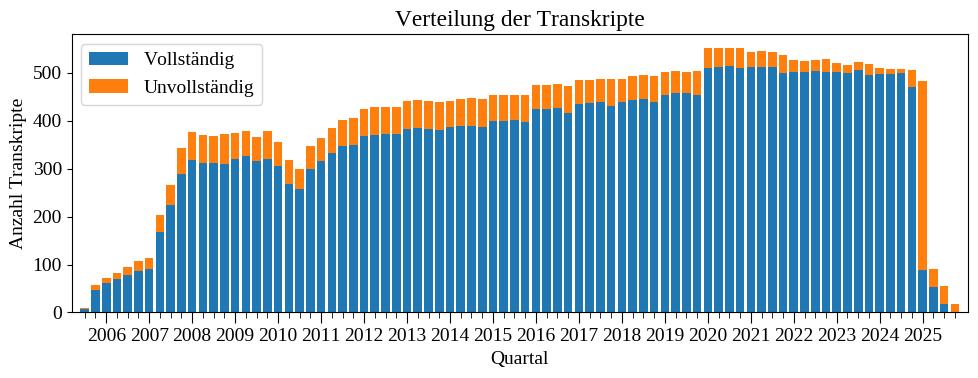

In [103]:
# Abbildung 1: Anzahl Transkripte je Quartal, gestapelt nach Vollständigkeit
fig, ax = plt.subplots(figsize=(10, 4))

ax.bar(summary.index, summary['non_nan'], label='Vollständig')
ax.bar(summary.index, summary['n_nan'], bottom=summary['non_nan'], label='Unvollständig')

periods = summary.index.tolist()
tick_positions, tick_labels = [], []
for i, p in enumerate(periods):
    if p.endswith('Q1'):
        tick_positions.append(i)
        tick_labels.append(p.split('_')[0])

# Hauptticks: einer je Jahr, beschriftet
ax.set_xticks(tick_positions)
ax.set_xticklabels(tick_labels)

# Nebenticks: einer je Quartal, unbeschriftet
ax.set_xticks(range(len(periods)), minor=True)
ax.tick_params(axis='x', which='minor', length=4)
ax.tick_params(axis='x', which='major', length=8)

ax.set_title("Verteilung der Transkripte")
ax.set_xlabel("Quartal")
ax.set_ylabel("Anzahl Transkripte")

ax.margins(x=0.01)
ax.legend()

plt.tight_layout()
plt.savefig('transcripts_distribution.png', dpi=300)
plt.show()

## 3 Verteilung der Features (Abbildung 2)

Gegenübergestellt werden die neun Sentiment-Dimensionen aus Versuch 1
(Mittelwert über die Frage-Antwort-Paare) und Versuch 2 (Bewertung des gesamten
Transkripts).

In [ ]:
# Feature-Spalten und Beschriftungen für beide Versuche vorbereiten
feature_cols_v4 = [c for c in df_v4.columns if "price" not in c and "move" not in c and c != "episode_id"]
# Passende _mean-Spalten aus Versuch 1
feature_cols_v3 = [f"{c}_mean" for c in feature_cols_v4]

# Beschriftungen: grossgeschrieben, ohne "_mean"
labels = [c.capitalize() for c in feature_cols_v4]

# Eine Farbe je Feature
colors = sns.color_palette("Set2", n_colors=len(labels))

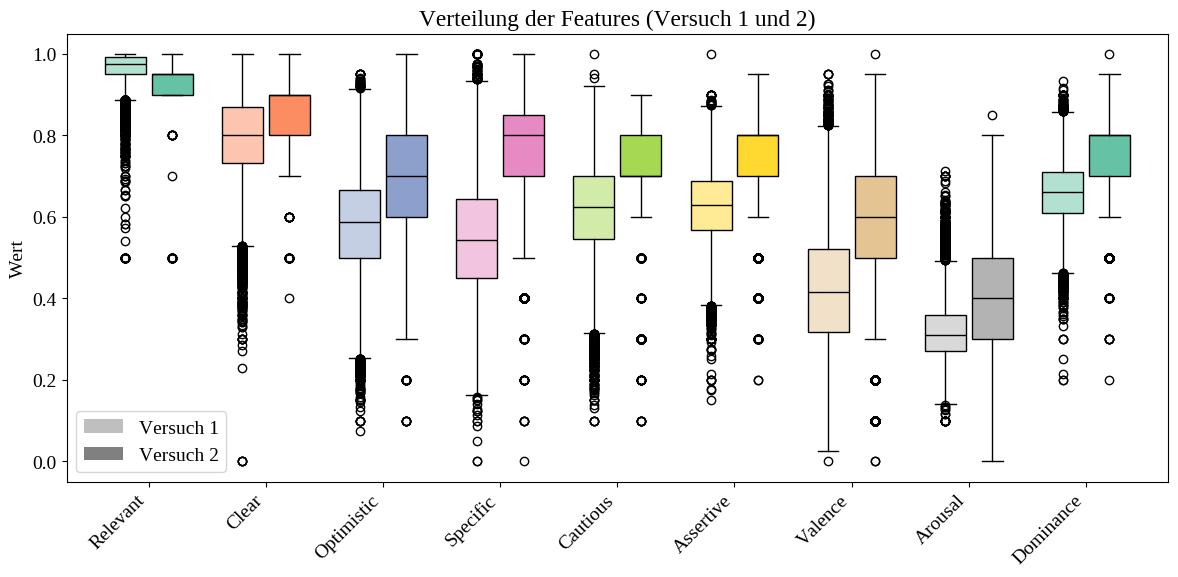

In [ ]:
# Boxplots paarweise je Feature: Versuch 1 transparent, Versuch 2 deckend
fig, ax = plt.subplots(figsize=(12, 6))
ax.grid(False)

width = 0.35   # schmalere Boxen
gap = 0.05     # kleiner Abstand zwischen den beiden Boxen eines Features
positions_v3 = np.arange(len(labels)) - (width / 2 + gap / 2)
positions_v4 = np.arange(len(labels)) + (width / 2 + gap / 2)

# Versuch 1
data_v3 = [df_v3[col].dropna().values for col in feature_cols_v3]
bp_v3 = ax.boxplot(data_v3, positions=positions_v3, widths=width,
                    patch_artist=True, showfliers=True,
                    medianprops={"color": "black"})

# Versuch 2
data_v4 = [df_v4[col].dropna().values for col in feature_cols_v4]
bp_v4 = ax.boxplot(data_v4, positions=positions_v4, widths=width,
                    patch_artist=True, showfliers=True,
                    medianprops={"color": "black"})

# Gleiche Farbe je Feature; die Transparenz unterscheidet die Versuche
for i, (box_v3, box_v4) in enumerate(zip(bp_v3["boxes"], bp_v4["boxes"])):
    box_v3.set_facecolor(to_rgba(colors[i], alpha=0.5))
    box_v3.set_edgecolor("black")

    box_v4.set_facecolor(to_rgba(colors[i], alpha=1.0))
    box_v4.set_edgecolor("black")

# Rahmen, Ticks und Beschriftungen durchgehend schwarz
for spine in ax.spines.values():
    spine.set_color("black")
ax.tick_params(colors="black")
ax.xaxis.label.set_color("black")
ax.yaxis.label.set_color("black")
ax.title.set_color("black")

ax.set_xticks(np.arange(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_ylabel("Wert")
ax.set_title("Verteilung der Features (Versuch 1 und 2)")

legend_elements = [
    Patch(facecolor="gray", alpha=0.5, label="Versuch 1"),
    Patch(facecolor="gray", alpha=1.0, label="Versuch 2"),
]
ax.legend(handles=legend_elements)

plt.tight_layout()
plt.savefig("feature_distribution.png", dpi=300)
plt.show()

## 4 Kursentwicklung und LLM-Vorhersagen (Abbildungen 3 und 4)

In [ ]:
# Ausreisser entfernen, identisch zu den ML-Training-Notebooks
s = df_v4["move_next_qtr"]

lower, upper = s.quantile([0.025, 0.975])

print(f"Lower bound (2.5th percentile): {lower:.4f}")
print(f"Upper bound (97.5th percentile): {upper:.4f}")
print("--")

df_filtered = df_v4[(df_v4['move_next_qtr'] >= lower) & (df_v4['move_next_qtr'] <= upper)].copy()

print(f"Original rows: {len(df_v4)}")
print(f"Filtered rows: {len(df_filtered)}")
print(f"Removed: {len(df_v4) - len(df_filtered)}")

Lower bound (2.5th percentile): -0.2847
Upper bound (97.5th percentile): 0.3588
--
Original rows: 32621
Filtered rows: 27486
Removed: 5135


In [ ]:
# Berichtsperiode ableiten und Zielvariable je Quartal um den Mittelwert bereinigen
df_filtered[['ticker', 'year', 'quarter']] = df_filtered.index.to_series().str.split('_', expand=True)
df_filtered['period'] = df_filtered['year'] + '_' + df_filtered['quarter']

# Bereinigte Zielvariable: Rendite relativ zum Quartalsmittel
df_filtered['y_relative'] = df_filtered['move_next_qtr'] - df_filtered.groupby('period')['move_next_qtr'].transform('mean')

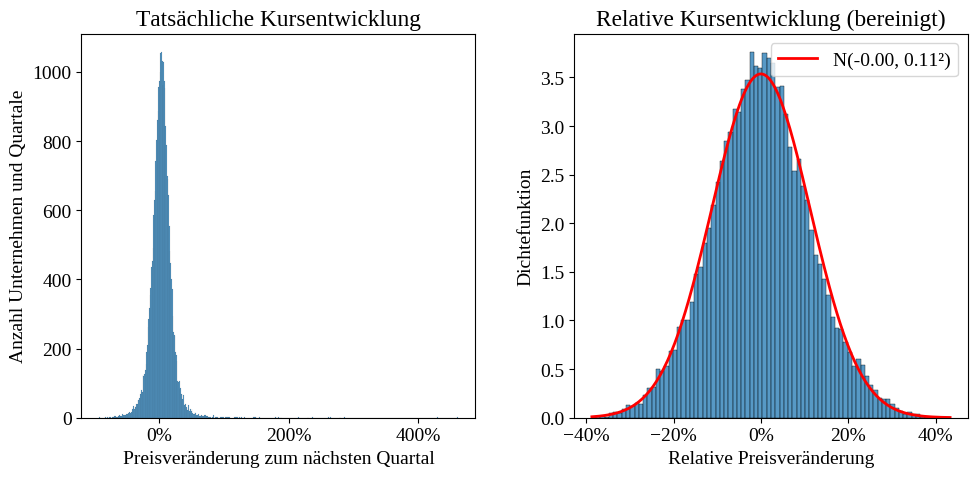

In [ ]:
# Abbildung 3: tatsächliche und relative (bereinigte) Kursentwicklung
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Links: Verteilung der tatsächlichen 90-Tage-Kursentwicklung
axes[0].set_title("Tatsächliche Kursentwicklung")
axes[0].set_xlabel("Preisveränderung zum nächsten Quartal")
axes[0].set_ylabel("Anzahl Unternehmen und Quartale")
sns.histplot(df_v4["move_next_qtr"], ax=axes[0])


# Rechts: bereinigte Kursentwicklung nach Entfernen der Ausreisser
sns.histplot(df_filtered["y_relative"], stat="density")

# Dichtefunktion der approximierten Normalverteilung
mean = df_filtered["y_relative"].mean()
std = df_filtered["y_relative"].std()

x = np.linspace(df_filtered["y_relative"].min(), df_filtered["y_relative"].max(), 200)
pdf = (1 / (std * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x - mean) / std) ** 2)

axes[1].set_title("Relative Kursentwicklung (bereinigt)")
axes[1].set_xlabel("Relative Preisveränderung")
axes[1].set_ylabel("Dichtefunktion")

# Kurve über das Histogramm legen
axes[1].plot(x, pdf, color="red", linewidth=2, label=f"N({mean:.2f}, {std:.2f}²)")
axes[1].legend()

for ax in axes.flat:
    ax.xaxis.set_major_formatter(ticker.PercentFormatter(xmax=1, decimals=0))

plt.tight_layout()
plt.subplots_adjust(wspace=0.25)

plt.savefig("price_movement.png", dpi=300)
plt.show()

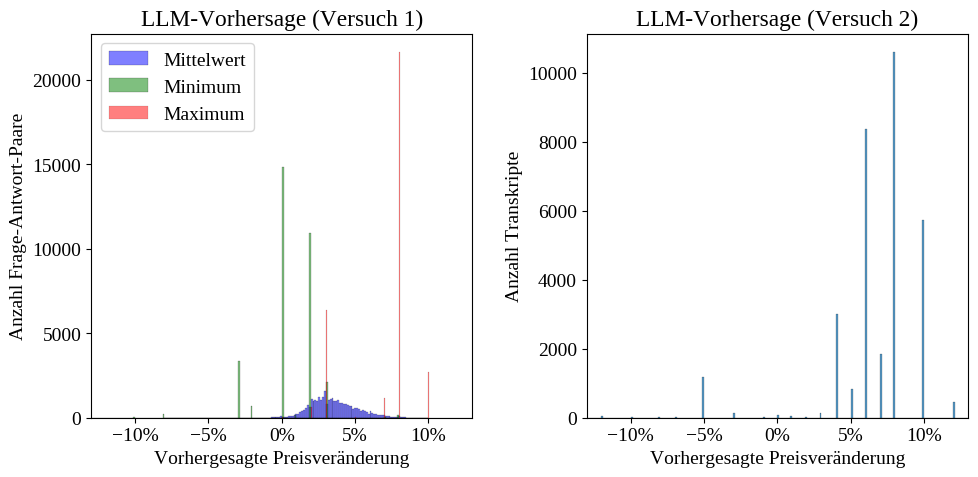

In [ ]:
# Abbildung 4: direkte Kursprognosen des LLM in beiden Versuchen
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Links: Versuch 1, aggregiert über die Frage-Antwort-Paare
axes[0].set_title("LLM-Vorhersage (Versuch 1)")
axes[0].set_xlabel("Vorhergesagte Preisveränderung")
axes[0].set_ylabel("Anzahl Frage-Antwort-Paare")
axes[0].set_xlim(-0.13, 0.13)

sns.histplot(df_v3["price_mean"], color="blue", label="Mittelwert", alpha=0.5, ax=axes[0])
sns.histplot(df_v3["price_min"], color="green", label="Minimum", alpha=0.5, ax=axes[0])
sns.histplot(df_v3["price_max"], color="red", label="Maximum", alpha=0.5, ax=axes[0])
axes[0].legend(loc="upper left")

# Rechts: Versuch 2, eine Prognose je Transkript
axes[1].set_title("LLM-Vorhersage (Versuch 2)")
axes[1].set_xlabel("Vorhergesagte Preisveränderung")
axes[1].set_ylabel("Anzahl Transkripte")
axes[1].set_xlim(-0.13, 0.13)

sns.histplot(df_v4["price_90d"], ax=axes[1])

for ax in axes.flat:
    ax.xaxis.set_major_formatter(ticker.PercentFormatter(xmax=1, decimals=0))

plt.tight_layout()
plt.subplots_adjust(wspace=0.3)

plt.savefig("llm_prediction.png", dpi=300)
plt.show()

## 5 Korrelation der Features (Abbildung 5)

Geprüft wird, wie stark die Dimensionen untereinander und mit der Zielvariable
korrelieren. Die Spalten der beiden Versuche stehen abwechselnd nebeneinander,
sodass sich je Dimension auch der Zusammenhang zwischen den Versuchen ablesen
lässt.

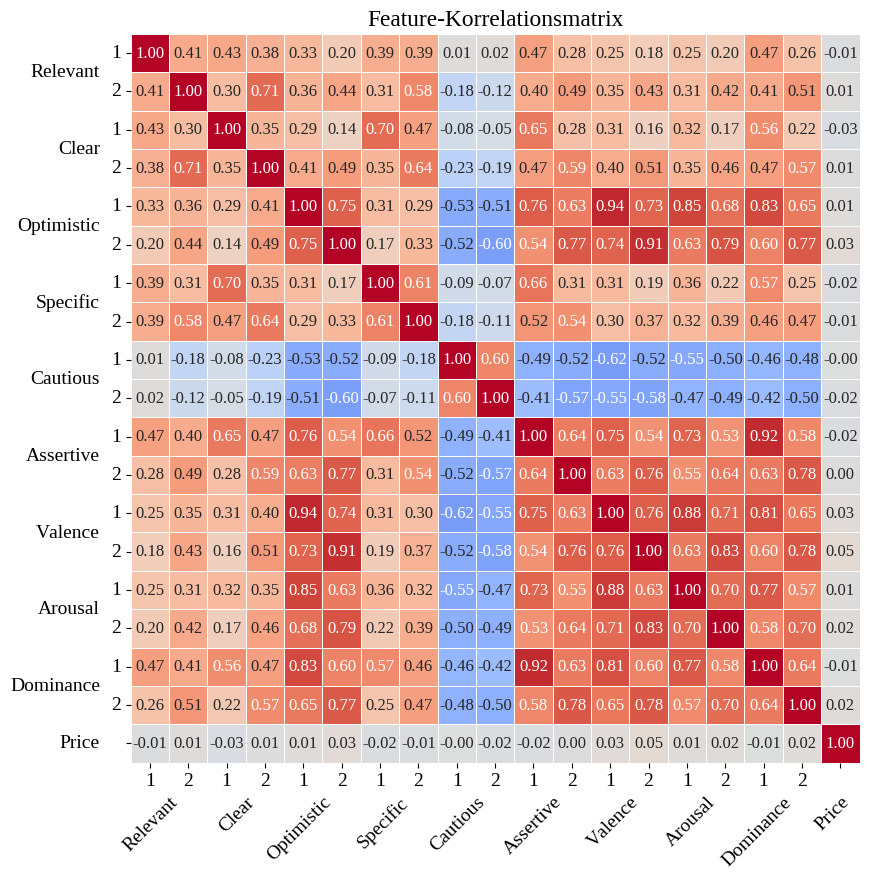

In [ ]:
# Korrelationsmatrix über beide Versuche und die Zielvariable
corr_data = pd.DataFrame()
for base_col in feature_cols_v4:
    corr_data[f"{base_col}_v3"] = df_v3[f"{base_col}_mean"]
    corr_data[f"{base_col}_v4"] = df_v4[base_col]

# Tatsächliche Kursentwicklung als letzte Spalte
corr_data["move_next_qtr"] = df_v4["move_next_qtr"]

# Achsen tragen nur "1"/"2"; der Feature-Name wird separat als Gruppenlabel gesetzt
short_labels = []
for _ in feature_cols_v4:
    short_labels.extend(["1", "2"])
short_labels.append("")  # Price Movement hat kein Versuch-Paar
feature_labels = [c.capitalize() for c in feature_cols_v4] + ["Price"]

# Korrelationsmatrix berechnen und darstellen
corr = corr_data.corr()
plt.figure(figsize=(10, 9))  # etwas mehr Höhe für die schrägen Labels
ax = sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
                  vmin=-1, vmax=1, square=True, linewidths=0.5,
                  annot_kws={"size": 12}, cbar=False,
                  xticklabels=short_labels, yticklabels=short_labels)

# Kurze "1"/"2"-Beschriftung auf beiden Achsen, nicht rotiert
ax.set_xticklabels(short_labels, rotation=0)
ax.set_yticklabels(short_labels, rotation=0)

# Feature-Namen als Gruppenlabel: links waagrecht, unten schräg
for i, label in enumerate(feature_labels):
    pos = len(corr) - 0.5 if label == "Price" else 2 * i + 1
    ax.text(-0.8, pos, label, ha="right", va="center")
    ax.text(pos, len(corr) + 0.8, label, ha="right", va="top",
         rotation=45, rotation_mode="anchor")

plt.title("Feature-Korrelationsmatrix")

plt.tight_layout()
plt.savefig("correlation_matrix.png", dpi=300)
plt.show()

## 6 Wichtigkeit der Features (Abbildung 6)

Dargestellt werden die Koeffizienten der linearen Regression aus Versuch 3, da
sie Richtung und Stärke des Zusammenhangs unmittelbar interpretierbar machen.

In [ ]:
# Trainiertes Modell aus Versuch 3 laden
linreg = joblib.load("/content/drive/MyDrive/Bachelorarbeit/models/linreg_v5.joblib")

In [ ]:
# Datensatz aus Versuch 3 für die Spaltennamen der Features
df_v5 = pd.read_csv('/content/drive/MyDrive/Bachelorarbeit/data/ml_data_v5.csv', index_col="episode_id")

In [ ]:
def rename_feature(feature):
    """Wandelt einen Spaltennamen in eine lesbare Beschriftung um.

    Die aggregierten Merkmale aus Versuch 1 tragen die Endungen _mean, _min und
    _max und werden als "V1", "Min" bzw. "Max" gekennzeichnet; Spalten ohne diese
    Endungen stammen aus Versuch 2 und erhalten das Kürzel "V2".
    """
    suffix_map = {"mean": "V1", "min": "Min", "max": "Max"}
    parts = feature.rsplit("_", 1)
    if len(parts) == 2 and parts[1] in suffix_map:
        base, suffix = parts
        label = suffix_map[suffix]
    else:
        base = feature
        label = "V2"
    return f"{base.capitalize()} {label}"

In [ ]:
# Koeffizienten den Features zuordnen und aufsteigend sortieren
importances = pd.Series(linreg.coef_, index=df_v5.drop("move_next_qtr", axis=1).columns)
importances.index = [rename_feature(f) for f in importances.index]
importances = importances.sort_values()

# Praktisch wirkungslose Features (Koeffizient nahe null) separat auflisten
zero_coefs = importances[abs(importances) < 0.01]
nonzero_coefs = importances[abs(importances) >= 0.01]

print("Features mit Koeffizient null:")
zero_coef_dict = {}
for key, value in zero_coefs.items():
  feature, version = key.split(" ")
  if not feature in zero_coef_dict:
    zero_coef_dict[feature] = [version]
  else:
    zero_coef_dict[feature].append(version)

for k, v in zero_coef_dict.items():
  print(f"{k} {v}", end=", ")

Features mit Koeffizient null:
Clear ['V1', 'Min', 'Max', 'V2'], Dominance ['V2'], Specific ['V1', 'V2', 'Min'], Arousal ['Min'], Relevant ['V2'], Valence ['Min'], Cautious ['V1', 'Max', 'Min', 'V2'], Optimistic ['Max'], 

/tmp/ipykernel_1578/1175805040.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=nonzero_coefs.values, y=nonzero_coefs.index, orient='h', palette="Spectral")


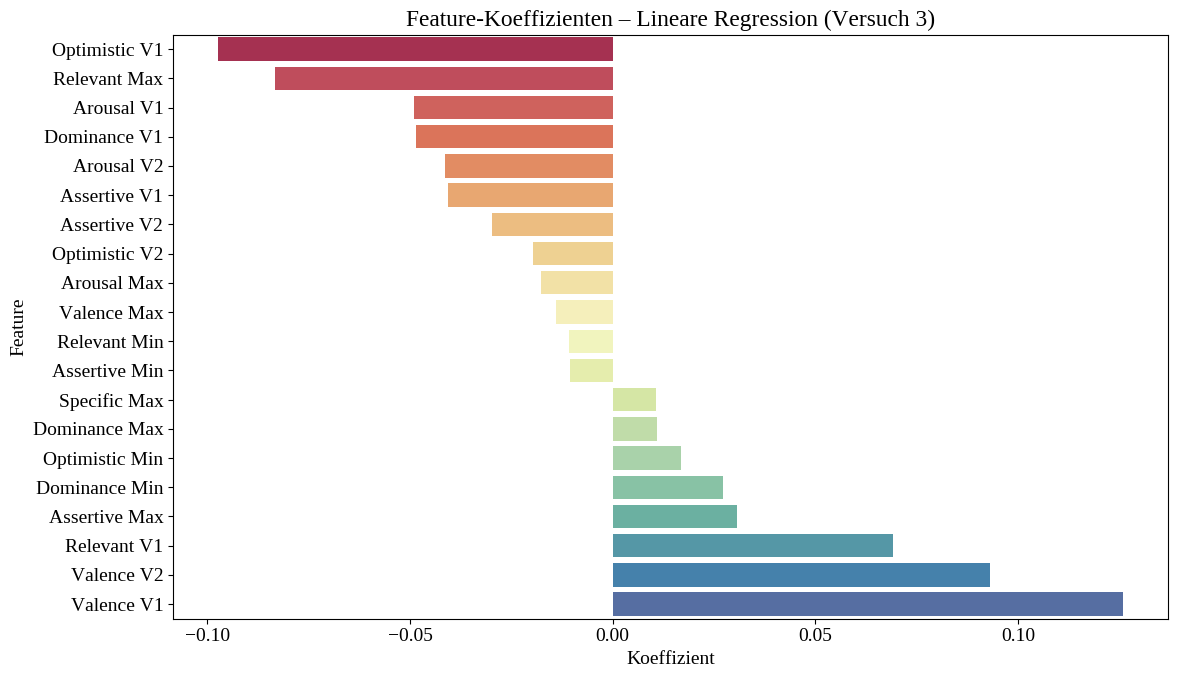

In [ ]:
# Abbildung 6: Koeffizienten der linearen Regression aus Versuch 3
plt.figure(figsize=(12, 7))
sns.barplot(x=nonzero_coefs.values, y=nonzero_coefs.index, orient='h', palette="Spectral")

plt.title("Feature-Koeffizienten – Lineare Regression (Versuch 3)")
plt.xlabel("Koeffizient")
plt.ylabel("Feature")

plt.tight_layout()
plt.savefig("feature_importance.png", dpi=300)
plt.show()

## 7 Tatsächliche Kursentwicklung und ML-Vorhersage (Abbildung 7)

In [21]:
# Vorhersagen der linearen Regression aus Versuch 3
y_pred_linreg = pd.read_csv('/content/drive/MyDrive/Bachelorarbeit/data/pred_v5.csv')['Linear Regression']

In [18]:
# Zugehörige tatsächliche (bereinigte) Werte der Testdaten
y_test = pd.read_csv('/content/drive/MyDrive/Bachelorarbeit/data/y_test.csv', index_col='episode_id')['y_relative']

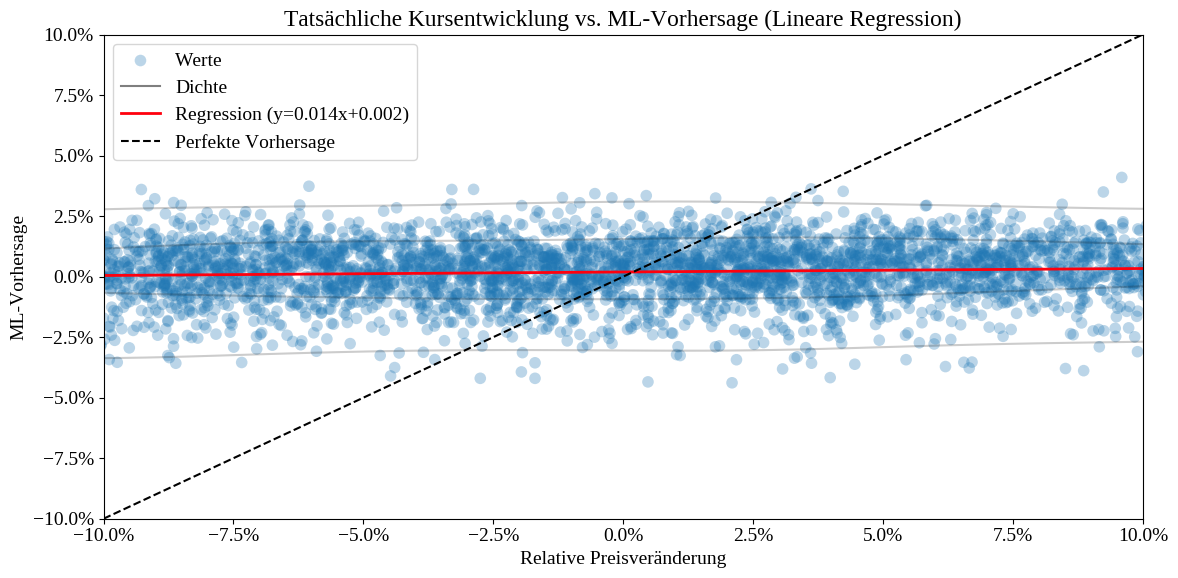

In [28]:
# Abbildung 7: Streudiagramm der Vorhersagen gegen die tatsächlichen Werte
x_vals = y_test.to_numpy()
y_vals = y_pred_linreg.to_numpy()

plt.figure(figsize=(12, 6))

sns.scatterplot(x=x_vals, y=y_vals, label='Werte', alpha=0.3, s=70, edgecolor='none')

sns.kdeplot(x=x_vals, y=y_vals, color='black', alpha=0.2, levels=3)

plt.plot([], [], color='black', alpha=0.5, label='Dichte')  # unsichtbarer Platzhalter für die Legende

min_val = -0.1
max_val = 0.1

# Ausgleichsgerade durch die Punktwolke
slope, intercept = np.polyfit(x_vals, y_vals, 1)
x_line = np.array([min_val, max_val])
y_line = slope * x_line + intercept
plt.plot(x_line, y_line, color='xkcd:bright red', linestyle='-', linewidth=2,
         label=f'Regression (y={slope:.3f}x+{intercept:.3f})')

# Diagonale der perfekten Vorhersage
plt.plot([min_val, max_val], [min_val, max_val], color='black', linestyle='--', label='Perfekte Vorhersage')

# Beschriftung
plt.xlabel("Relative Preisveränderung")
plt.ylabel("ML-Vorhersage")
plt.title("Tatsächliche Kursentwicklung vs. ML-Vorhersage (Lineare Regression)")
plt.legend()

plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)

# Achsen in Prozent formatieren
ax = plt.gca()
ax.xaxis.set_major_formatter(ticker.PercentFormatter(xmax=1, decimals=1))
ax.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1, decimals=1))

# Grafik speichern
plt.tight_layout()
plt.savefig('actual_predicted_returns.png', dpi=300)
plt.show()

## 8 Kumulierte Rendite (Abbildung 8)

Für die Grafik wird die Long-Short Rendite über den gesamten Zeitraum berechnet,
also auch über die Trainingsjahre. Die im Diagramm eingezeichnete Linie markiert
den Train/Test-Split; erst rechts davon liegt eine echte Prognoseleistung vor.

In [ ]:
# Datensatz aus Versuch 3 laden und Beobachtungen ohne Zielvariable entfernen
df_v5 = pd.read_csv('/content/drive/MyDrive/Bachelorarbeit/data/ml_data_v5.csv', index_col="episode_id")
df_v5 = df_v5.dropna(axis = 0, subset = ["move_next_qtr"])

In [ ]:
# Ausreisser entfernen, identisch zu den ML-Training-Notebooks
s = df_v5["move_next_qtr"]

lower, upper = s.quantile([0.025, 0.975])

print(f"Lower bound (2.5th percentile): {lower:.4f}")
print(f"Upper bound (97.5th percentile): {upper:.4f}")
print("--")

df_filtered = df_v5[(df_v5['move_next_qtr'] >= lower) & (df_v5['move_next_qtr'] <= upper)].copy()

print(f"Original rows: {len(df_v5)}")
print(f"Filtered rows: {len(df_filtered)}")
print(f"Removed: {len(df_v5) - len(df_filtered)}")

Lower bound (2.5th percentile): -0.2847
Upper bound (97.5th percentile): 0.3588
--
Original rows: 28934
Filtered rows: 27486
Removed: 1448


In [ ]:
# Gesamter Datensatz als Eingabe, nicht nur die Testdaten
X_test = df_filtered.drop("move_next_qtr", axis=1)  # gesamter Zeitraum für die Grafik
y_actual = df_filtered["move_next_qtr"]

In [ ]:
# Angepasste Fassung der Funktion aus den ML-Training-Notebooks: Sie gibt nur die
# Quartalsrenditen zurück, da für die Grafik keine Fehlermasse benötigt werden.

def long_short_returns(y_pred, actual, top_pct=0.2):
    """Berechnet die Long-Short Rendite je Quartal.

    Je Quartal werden alle Unternehmen absteigend nach der vorhergesagten
    Kursentwicklung sortiert. Auf das obere Quantil wird eine Long-Position, auf
    das untere eine Short-Position simuliert; die mittleren 60% werden ignoriert.
    """
    df = pd.DataFrame({'pred': y_pred, 'actual': actual})  # Vorhersage und Realität in einer Tabelle

    parts = df.index.to_series().str.split('_', expand=True)  # "AAL_2019_Q2" -> ['AAL', '2019', 'Q2']
    df['period'] = parts[1] + '_' + parts[2]  # als "2019_Q2" für die Gruppierung je Quartal

    results = {}  # eine Long-Short Rendite je Quartal
    for period, g in df.groupby('period'):  # über die Quartale iterieren
        g = g.sort_values('pred', ascending=False)  # nach Vorhersage sortieren, höchste zuerst
        n = max(1, int(len(g) * top_pct))  # Korbgrösse (oberste/unterste top_pct%), mindestens 1 Titel

        long_ret = g['actual'].iloc[:n].mean()  # durchschnittliche Rendite des Long-Korbs
        short_ret = g['actual'].iloc[-n:].mean()  # durchschnittliche Rendite des Short-Korbs

        results[period] = long_ret - short_ret  # Differenz als Long-Short Rendite des Quartals

    q_ret = pd.Series(results).sort_index()  # Quartalsrenditen in chronologischer Reihenfolge

    return q_ret

In [ ]:
# Kontrolle: Sharpe-Quotient über den Testzeitraum muss mit der
# Ergebnistabelle aus "RESULTS Processing.ipynb" übereinstimmen
linreg = joblib.load("/content/drive/MyDrive/Bachelorarbeit/models/linreg_v5.joblib")

y_pred_linreg = linreg.predict(X_test)

q_ret_linreg = long_short_returns(y_pred_linreg, y_actual)

# Nur die Quartale ab 2022 (Testzeitraum) heranziehen
q_ret_linreg_test = q_ret_linreg[q_ret_linreg.index.to_series().str.split('_', expand=True)[0] >= "2022"]
print(f"Sharpe: {q_ret_linreg_test.mean() / q_ret_linreg_test.std():.2f}")

Sharpe: 1.28


In [ ]:
# Dateinamen der gespeicherten Modelle und ihre Beschriftung in der Grafik;
# "*" kennzeichnet die getunte Variante
models = {
    'linreg': 'Lineare Regression',
    'ridge': 'Ridge', 'ridge_search': 'Ridge*',
    'lasso': 'Lasso', 'lasso_search': 'Lasso*',
    'mlp': 'Neural Network', 'mlp_search': 'Neural Network*',
    'forest': 'Random Forest', 'forest_search': 'Random Forest*',
    'xgb': 'XGBoost', 'xgb_search': 'XGBoost*',
    'lgbm': 'LightGBM', 'lgbm_search': 'LightGBM*',
}

In [ ]:
# Alle Modelle laden und ihre Quartalsrenditen berechnen
results = {}

for file, name in models.items():
    model = joblib.load(f"/content/drive/MyDrive/Bachelorarbeit/models/{file}_v5.joblib")
    y_pred = model.predict(X_test)

    results[name] = long_short_returns(y_pred, y_actual)

q_returns = pd.DataFrame(results)

In [ ]:
# Quartalsrenditen je Modell zur Sichtprüfung
q_returns

,Lineare Regression,Ridge,Ridge*,Lasso,Lasso*,Neural Network,Neural Network*,Random Forest,Random Forest*,XGBoost,XGBoost*,LightGBM,LightGBM*
2005_Q4,0.031378,0.031378,0.031378,0.019675,0.030381,0.026099,0.043085,0.238450,0.052943,0.156887,0.069182,0.127040,0.047610
2006_Q1,0.019142,0.032001,0.032001,0.032001,0.026130,0.031744,0.094738,0.301872,0.068314,0.257854,0.082310,0.203977,0.039725
2006_Q2,-0.026960,-0.046585,-0.046585,-0.046585,-0.060258,-0.135879,-0.006507,0.317019,0.009180,0.239954,0.024885,0.175621,0.015045
2006_Q3,0.081624,0.116076,0.116076,0.146875,0.128619,0.092145,0.126372,0.351135,0.143150,0.261005,0.136413,0.238104,0.105355
2006_Q4,0.087240,0.087232,0.087232,0.075822,0.111086,0.034100,0.084921,0.343890,0.112966,0.291517,0.095531,0.245257,0.097062
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024_Q3,0.095555,0.090343,0.090343,0.098576,0.096745,0.089135,0.092862,0.037918,0.088232,0.028192,0.090023,0.076674,0.089331
2024_Q4,0.025394,0.030822,0.030822,0.030546,0.029528,0.030606,0.012844,0.019212,0.048991,-0.005716,0.032846,0.034858,0.045297
2025_Q1,0.081302,0.087191,0.087191,0.089571,0.082173,0.002708,0.091884,0.021261,0.081990,0.000973,0.071340,0.064421,0.069495
2025_Q2,0.109087,0.109087,0.109087,0.106095,0.046046,0.031268,0.144667,0.014642,0.067460,0.215184,0.052411,0.078163,0.052422


In [ ]:
# Summe der Quartalsrenditen des besten Modells
print(f"{q_returns['Neural Network*'].sum():.1%}")

371.7%


### 7.1 Rendite des S&P 500 als Vergleichsgrösse

In [ ]:
# yfinance liefert die historischen Kurse des Index
import yfinance as yf

In [ ]:
# Quartalsrenditen des S&P 500 als Vergleichsgrösse aufbereiten

# Tagesschlusskurse des Index herunterladen
sp500 = yf.Ticker("^GSPC")
data = sp500.history(start="2005-06-01", end="2025-10-01")["Close"]

# Auf Quartalsende resamplen (letzter Handelstag je Quartal)
quarterly_close = data.resample("QE").last()

# Prozentuale Veränderung von Quartal zu Quartal berechnen
quarterly_returns = quarterly_close.pct_change().dropna()

# Index in das Format "JJJJ_Qn" umbenennen
quarterly_returns.index = [f"{ts.year}_Q{ts.quarter}" for ts in quarterly_returns.index]

In [ ]:
# Auf den Zeitraum des Datensatzes einschränken
sp500_returns = quarterly_returns.loc["2005_Q4":"2025_Q3"]

sp500_returns

,Close
2005_Q4,0.015853
2006_Q1,0.037315
2006_Q2,-0.019052
2006_Q3,0.051685
2006_Q4,0.061721
...,...
2024_Q3,0.055306
2024_Q4,0.020677
2025_Q1,-0.045868
2025_Q2,0.105687


### 7.2 Grafik

In [ ]:
def quarter_to_date(q_str):
    """Wandelt '2021_Q4' in den letzten Tag des Quartals um (Timestamp)."""
    year, quarter = q_str.split('_')
    period = pd.Period(f"{year}{quarter}", freq='Q')
    return period.end_time.normalize()

In [ ]:
# Kumulierte Rendite je Modell und für den Index berechnen
dates = q_returns.index.map(quarter_to_date)

# Kumulierte Rendite (Wert von einer investierten Geldeinheit)
cum_returns = (1 + q_returns).cumprod()
cum_returns.index = dates

# Startpunkt 1.0 direkt vor dem ersten Quartal einfügen, damit alle Linien
# auf derselben Höhe beginnen
start_date = dates[0] - pd.DateOffset(days=1)
start_row = pd.DataFrame(
    [[1.0] * cum_returns.shape[1]],
    columns=cum_returns.columns,
    index=[start_date]
)
cum_returns = pd.concat([start_row, cum_returns]).sort_index()

# Vergleichsgrösse S&P 500 analog kumulieren
sp500_dates = sp500_returns.index.map(quarter_to_date)
sp500_cum = (1 + sp500_returns).cumprod()
sp500_cum.index = sp500_dates
sp500_cum = pd.concat([pd.Series([1.0], index=[start_date]), sp500_cum]).sort_index()
sp500_cum_pct = (sp500_cum - 1) * 100

sp500_color = "black"

In [ ]:
# Einzelne Werte für den Fliesstext der Arbeit
print(f"Neural Network (t): {cum_returns['Neural Network*'].iloc[-1]:,.1%}")
print(f"Random Forest: {cum_returns['Random Forest'].loc['2021-12-31']:,.1%}")

Neural Network (t): 3,614.1%
Random Forest: 3,726,629,258.4%


In [ ]:
# Die Boosting- und Tree-Modelle erreichen deutlich höhere Werte und werden
# daher in einem zweiten Diagramm mit logarithmischer Skala dargestellt
log_scale_models = {'Random Forest', 'Random Forest*', 'XGBoost', 'XGBoost*', 'LightGBM', 'LightGBM*'}

def base_name(col):
    return col[:-1] if col.endswith('*') else col

# Kumulierte Rendite in Prozent statt als Multiplikator (20 -> 1900%, nicht 2000%)
cum_returns_pct = (cum_returns - 1) * 100

# Eine Farbe je Basismodell; getunte und ungetunte Variante teilen sie sich
base_names = list(dict.fromkeys(base_name(c) for c in cum_returns_pct.columns))
palette = sns.color_palette("bright", n_colors=len(base_names))
color_map = {name: palette[i] for i, name in enumerate(base_names)}

In [ ]:
# Zeichnet einen Satz Modelle in eine Achse: durchgezogen = Standardmodell,
# gestrichelt = getunte Variante
def plot_subset(ax, columns, log=False):
    plotted_bases = []
    for col in columns:
        name = base_name(col)
        color = color_map[name]
        linestyle = '--' if col.endswith('*') else '-'
        ax.plot(
            cum_returns_pct.index, cum_returns_pct[col],
            color=color, linestyle=linestyle, linewidth=1.5
        )
        if name not in plotted_bases:
            plotted_bases.append(name)

    # Vergleichsgrösse S&P 500
    ax.plot(
        sp500_cum_pct.index, sp500_cum_pct.values,
        color=sp500_color, linewidth=2, linestyle='-'
    )

    ax.axvline(pd.Timestamp("2022-01-01"), color='black', linestyle='--', linewidth=1.5, alpha=0.7)

    ax.grid(True, alpha=0.3)
    if log:
        ax.set_yscale('symlog', linthresh=100)
        y_min = min(cum_returns_pct[columns].min().min(), sp500_cum_pct.min())
        y_max = max(cum_returns_pct[columns].max().max(), sp500_cum_pct.max())
        ax.set_ylim(y_min * 1.5 if y_min < 0 else y_min * 0.5, y_max * 1.5)

    # Legende: ein Farbpunkt je Modell sowie Index und Train/Test-Split
    legend_handles = [
        Line2D([0], [0], marker='o', linestyle='None', markersize=9, color=color_map[name])
        for name in plotted_bases
    ]
    legend_labels = list(plotted_bases)

    legend_handles.append(Line2D([0], [0], marker='o', linestyle='None', markersize=9, color=sp500_color))
    legend_labels.append('S&P 500')

    legend_handles.append(Line2D([0], [0], color='black', linestyle='--', linewidth=1.5))
    legend_labels.append('Train/Test-Split')

    ax.legend(
        legend_handles, legend_labels,
        loc='lower center', bbox_to_anchor=(0.5, -0.25),
        ncol=len(legend_labels), fontsize=12, frameon=False
    )

    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right')

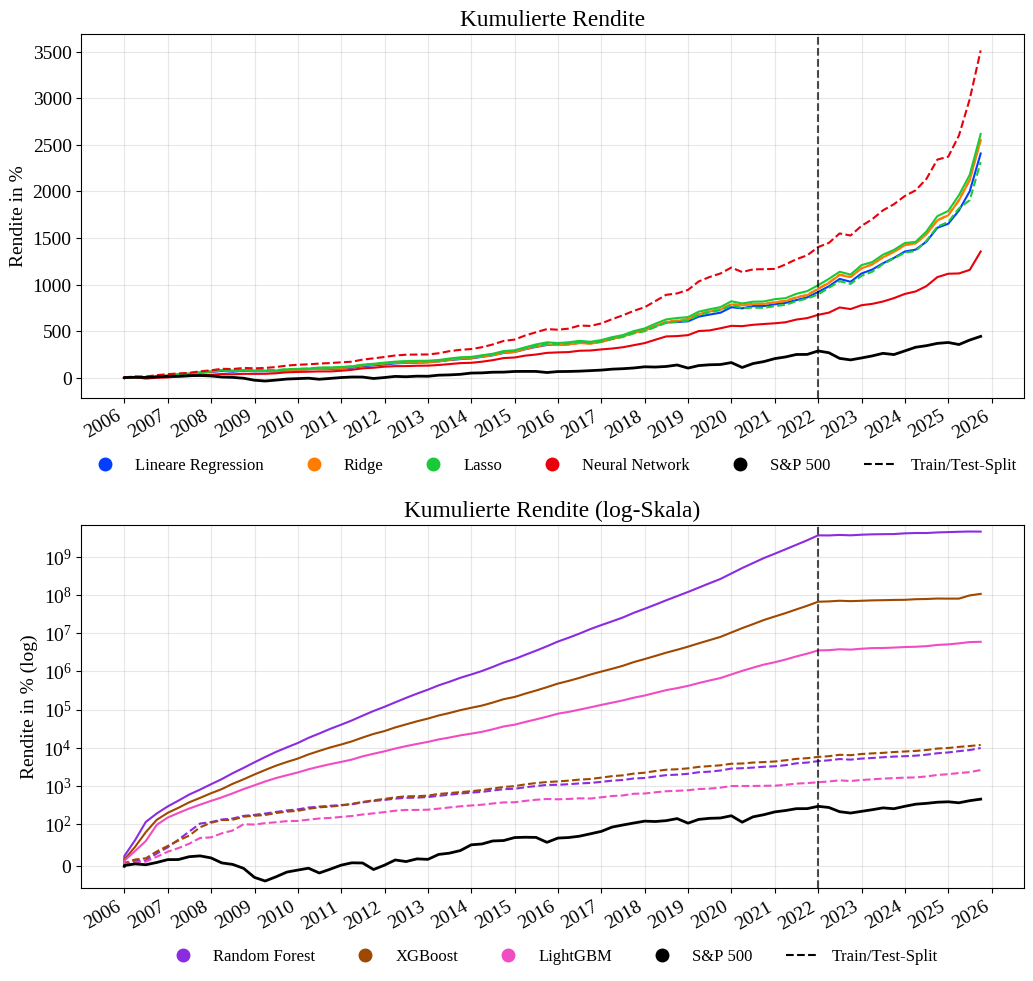

In [ ]:
# Abbildung 8: kumulierte Rendite, oben linear, unten logarithmisch
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 10))

normal_cols = [c for c in cum_returns_pct.columns if base_name(c) not in log_scale_models]
log_cols = [c for c in cum_returns_pct.columns if base_name(c) in log_scale_models]

plot_subset(ax1, normal_cols, log=False)
plot_subset(ax2, log_cols, log=True)

ax1.set_title("Kumulierte Rendite")
ax2.set_title("Kumulierte Rendite (log-Skala)")

ax1.set_ylabel("Rendite in %")
ax2.set_ylabel("Rendite in % (log)")

plt.tight_layout()
plt.subplots_adjust(hspace=0.35)

plt.savefig('cumulative_returns.png', dpi=300)
plt.show()